In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph,START,END
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver
from pydantic import BaseModel,Field
from typing import Literal

In [4]:
class FlowState(BaseModel):
    question:str=Field(description='This is for the user question')
    category:Literal['coding','google_search','weather']=Field(default='google_search')
    answer:str=Field(default="")

In [5]:
class Question_Category(BaseModel):
    category:Literal['coding','google_search','weather']=Field(default="google_search")

In [6]:
llm=ChatGroq(model="openai/gpt-oss-20b")
memory=InMemorySaver()

In [7]:
def check_question_category(state: FlowState) -> FlowState:
    structured_llm = llm.with_structured_output(
        Question_Category,
        method="json_mode"
    )

    res = structured_llm.invoke(
        f"""
        Categorize the following question into exactly one category:
        - coding
        - google_search
        - weather

        Return JSON only, in this format:
        {{"category": "weather"}}

        Question: {state.question}
        """
    )

    state.category = res.category
    return state

In [8]:
# Decider
def route(state:FlowState)->Literal['coding','google_search','weather']:
    return state.category

# **Nodes**

In [9]:
def coding(state:FlowState)->FlowState:
    res=llm.invoke(f'You are an Expert Coder solve this question:{state.question}')
    state.answer=res.content
    return state

def google_search(state:FlowState)->FlowState:
    print("Google Search in progress")
    return state

def weather(state:FlowState)->FlowState:
    print("weather api")
    return state


    

In [10]:
graph=StateGraph(FlowState)

graph.add_node("Question_Category",check_question_category)
graph.add_node("coding",coding)
graph.add_node("google_search",google_search)
graph.add_node("weather",weather)

graph.add_edge(START,"Question_Category")
graph.add_conditional_edges("Question_Category",route)
graph.add_edge("coding",END)
graph.add_edge("google_search",END)
graph.add_edge("weather",END)

graph=graph.compile()

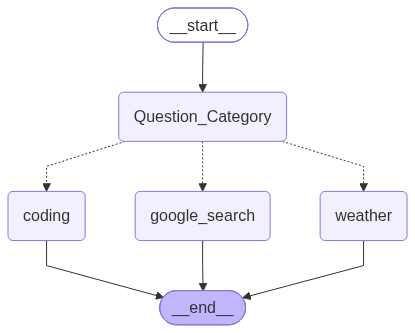

In [11]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [12]:
config={"configurable":{"thread_id":"122"}}

In [16]:
response=graph.invoke({"question":"write a program to add 3 numbers in python?"})
print(response)

{'question': 'write a program to add 3 numbers in python?', 'category': 'coding', 'answer': 'Sure!  \nBelow is a simple Python program that reads three numbers from the user, adds them together, and prints the result.\n\n```python\n# ----------------------------------------------------\n#  Add 3 Numbers in Python\n# ----------------------------------------------------\n# 1. Prompt the user for three numbers\nnum1 = float(input("Enter the first number: "))\nnum2 = float(input("Enter the second number: "))\nnum3 = float(input("Enter the third number: "))\n\n# 2. Add the numbers\ntotal = num1 + num2 + num3\n\n# 3. Display the result\nprint(f"The sum of {num1}, {num2} and {num3} is: {total}")\n```\n\n### How it works\n1. **Reading input** – `input()` reads a line from the keyboard as a string.  \n   We immediately convert that string to a `float` (you can use `int` if you only want integer values).\n\n2. **Adding** – The three variables `num1`, `num2`, and `num3` are added together using t

In [18]:
print(response['answer'])

Sure!  
Below is a simple Python program that reads three numbers from the user, adds them together, and prints the result.

```python
# ----------------------------------------------------
#  Add 3 Numbers in Python
# ----------------------------------------------------
# 1. Prompt the user for three numbers
num1 = float(input("Enter the first number: "))
num2 = float(input("Enter the second number: "))
num3 = float(input("Enter the third number: "))

# 2. Add the numbers
total = num1 + num2 + num3

# 3. Display the result
print(f"The sum of {num1}, {num2} and {num3} is: {total}")
```

### How it works
1. **Reading input** – `input()` reads a line from the keyboard as a string.  
   We immediately convert that string to a `float` (you can use `int` if you only want integer values).

2. **Adding** – The three variables `num1`, `num2`, and `num3` are added together using the `+` operator.

3. **Printing** – The `print()` function shows the result.  
   The `f`‑string (`f"..."`) lets us 